# Experimento 2 — Afinidade melhora a previsão?

**Hipótese:** acrescentar afinidade às duas médias reduz o RMSE e os padrões nos resíduos.

Afinidade é a proporção do histórico correspondente ao gênero do filme: `share_action`, `share_comedy` ou `share_drama`. Se 70% do histórico é ação, a afinidade para um filme de ação é 0,70.

Comparamos duas médias com duas médias + afinidade. São regressões com intercepto, sem regularização ou busca; o candidato supõe um efeito linear da afinidade comum aos gêneros.

### O que este experimento traz de novo

| | |
|---|---|

| **Ponto de partida** | Regressão com as duas médias (experimento 1, RMSE 0,8396). |
| **O que muda** | Um atributo novo, a afinidade $a$. O modelo continua o mesmo. |
| **Modelo** | $\hat y=b_0+b_u u+b_m m+b_a a$, por mínimos quadrados. |
| **Por que esta mudança** | Na EDA, o efeito de `share_drama` sobre a nota muda de sinal conforme o gênero do filme: é uma **interação** entre `share_*` e `genre`. A regressão só soma atributos, com o mesmo peso para todos os filmes, e por isso não constrói essa interação sozinha. A afinidade entrega a interação pronta, como um único atributo. |
| **Como ler o resultado** | Um ganho grande indica que a interação gênero × gosto do usuário era a principal estrutura que faltava ao modelo. |

**Protocolo:** 5 dobras × 5 repetições, semente 2026; mesmas partições para os modelos, apenas `train.csv`, previsões cortadas em [0, 5].

O RMSE considera as cinco previsões fora da dobra (OOF) de cada linha separadamente. Só os gráficos usam a média dessas previsões. As partições compartilham treino: desvios e vitórias são descritivos, não testes de significância. As hipóteses vieram da exploração destes dados; não são confirmação independente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True
N_BINS = 8  # Somente visualização; não modifica os modelos.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
df = pd.read_csv(ROOT / 'data' / 'train.csv')
genres = ['action', 'comedy', 'drama']
assert set(df['genre'].unique()).issubset(genres)
required = ['user_avg_stars', 'movie_avg_stars', 'stars'] + ['share_' + g for g in genres]
assert not df[required].isna().any().any()
df['affinity'] = [row['share_' + row['genre']] for _, row in df.iterrows()]
assert df['affinity'].between(0, 1).all()
y = df['stars'].to_numpy(dtype=float)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
display(df[['genre', 'share_action', 'share_comedy', 'share_drama', 'affinity']].head())
print(f'{len(df)} linhas; {N_SPLITS} folds × {N_REPEATS} repetições; semente {SEED}; corte: {CLIP}')

,genre,share_action,share_comedy,share_drama,affinity
0,drama,0.315,0.501,0.184,0.184
1,action,0.180,0.151,0.669,0.180
2,action,0.701,0.258,0.041,0.701
3,action,0.700,0.204,0.096,0.700
4,action,0.621,0.257,0.122,0.621


4000 linhas; 5 folds × 5 repetições; semente 2026; corte: True


## 1. Previsões fora da dobra

Recalculamos ambos os modelos para executar este notebook de forma independente. A equação linear é calculada explicitamente, com verificação de valores finitos antes do corte.

In [2]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

def predict_linear(model, X):
    prediction = np.sum(X * model.coef_, axis=1) + model.intercept_
    assert np.isfinite(prediction).all()
    return np.clip(prediction, 0, 5) if CLIP else prediction

candidates = {
    'Duas médias': ['user_avg_stars', 'movie_avg_stars'],
    'Duas médias + afinidade': ['user_avg_stars', 'movie_avg_stars', 'affinity'],
}
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(df))
predictions_by_repeat = {name: np.full((N_REPEATS, len(df)), np.nan) for name in candidates}
rows = []
for name, columns in candidates.items():
    X = df[columns].to_numpy(dtype=float)
    for fold, (train, valid) in enumerate(folds, start=1):
        model = LinearRegression().fit(X[train], y[train])
        pred = predict_linear(model, X[valid])
        predictions_by_repeat[name][(fold - 1) // N_SPLITS, valid] = pred
        rows.append({'modelo': name, 'fold': fold,
                     'E_CV': rmse(y[valid], pred),
                     'E_in': rmse(y[train], predict_linear(model, X[train]))})
assert all(np.isfinite(values).all() for values in predictions_by_repeat.values())
oof = pd.DataFrame({name: values.mean(axis=0) for name, values in predictions_by_repeat.items()})
by_fold = pd.DataFrame(rows)
residuals = oof.apply(lambda prediction: y - prediction)
print('Previsões OOF disponíveis para todas as linhas e ambos os modelos.')

Previsões OOF disponíveis para todas as linhas e ambos os modelos.


## 2. Resíduos antes de incluir afinidade

Resíduo positivo indica subestimação; negativo, superestimação. As faixas são quantis dentro de cada gênero e podem ter limites diferentes. As curvas mostram médias, não a dispersão individual.

,genero,faixa,afinidade_media,residuo_medio,n
0,action,"(0.049, 0.235]",0.162,-0.997,184
1,action,"(0.235, 0.321]",0.280,-0.221,184
2,action,"(0.321, 0.39]",0.354,0.085,180
3,action,"(0.39, 0.456]",0.425,0.241,183
4,action,"(0.456, 0.537]",0.498,0.419,183
5,action,"(0.537, 0.621]",0.579,0.494,182
6,action,"(0.621, 0.691]",0.658,0.533,183
7,action,"(0.691, 0.862]",0.749,0.555,183
8,comedy,"(0.068, 0.188]",0.152,-1.108,160
9,comedy,"(0.188, 0.23]",0.209,-0.667,154


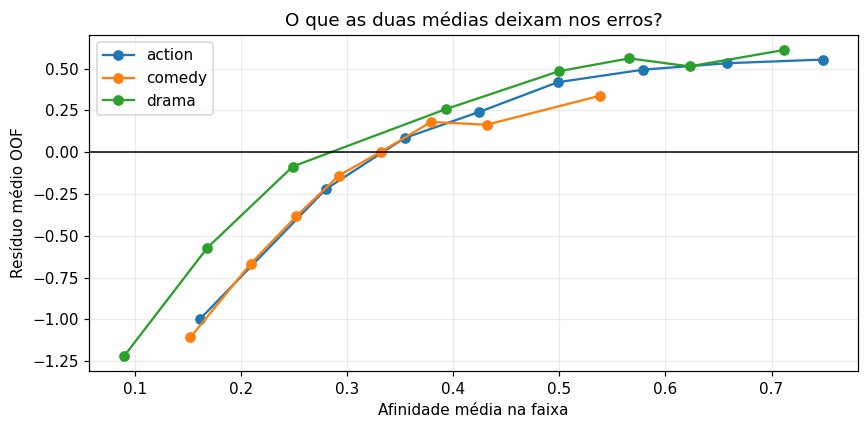

In [3]:
def residual_by_bin(model_name):
    tables = []
    for genre in genres:
        sub = df.loc[df['genre'].eq(genre), ['affinity']].copy()
        sub['residuo'] = residuals.loc[sub.index, model_name]
        sub['faixa'] = pd.qcut(sub['affinity'], N_BINS, duplicates='drop')
        table = sub.groupby('faixa', observed=True).agg(
            afinidade_media=('affinity', 'mean'), residuo_medio=('residuo', 'mean'),
            n=('residuo', 'size')).reset_index()
        table.insert(0, 'genero', genre)
        tables.append(table)
    return pd.concat(tables, ignore_index=True)

baseline_bins = residual_by_bin('Duas médias')
display(baseline_bins.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
for genre in genres:
    sub = baseline_bins[baseline_bins['genero'].eq(genre)]
    ax.plot(sub['afinidade_media'], sub['residuo_medio'], 'o-', label=genre)
ax.axhline(0, color='black', linewidth=1)
ax.set(xlabel='Afinidade média na faixa', ylabel='Resíduo médio OOF',
       title='O que as duas médias deixam nos erros?')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Ganho ao incluir afinidade

Diferenças de RMSE negativas favorecem o candidato. Observe magnitude e consistência entre partições.

In [4]:
summary = by_fold.groupby('modelo', sort=False).agg(
    E_CV=('E_CV', 'mean'),
    desvio_E_CV=('E_CV', 'std'),
    E_in=('E_in', 'mean'))
summary.insert(0, 'RMSE OOF repetido', [rmse(y, predictions_by_repeat[name]) for name in summary.index])
display(summary.round(4))
paired = by_fold.pivot(index='fold', columns='modelo', values='E_CV')
paired['Diferença: com − sem afinidade'] = paired['Duas médias + afinidade'] - paired['Duas médias']
display(paired.round(4))
gain = summary.loc['Duas médias', 'RMSE OOF repetido'] - summary.loc['Duas médias + afinidade', 'RMSE OOF repetido']
wins = int((paired['Diferença: com − sem afinidade'] < 0).sum())
print(f'Redução de RMSE OOF: {gain:.4f} estrela(s). Menor erro em {wins}/{N_SPLITS * N_REPEATS} partições.')
print('Resultado compatível com a hipótese de ganho preditivo.' if gain > 0
      else 'O resultado não sustentou a hipótese de ganho preditivo neste protocolo.')

,RMSE OOF repetido,E_CV,desvio_E_CV,E_in
modelo,,,,
Duas médias,0.8396,0.8394,0.0185,0.8385
Duas médias + afinidade,0.6601,0.6599,0.0137,0.6591


modelo,Duas médias,Duas médias + afinidade,Diferença: com − sem afinidade
fold,,,
1,0.8470,0.6544,-0.1927
2,0.8545,0.6589,-0.1956
3,0.8284,0.6485,-0.1799
4,0.8599,0.6832,-0.1766
5,0.8068,0.6542,-0.1526
6,0.8337,0.6720,-0.1616
7,0.8617,0.6716,-0.1901
8,0.8392,0.6493,-0.1899
9,0.8521,0.6619,-0.1902


Redução de RMSE OOF: 0.1795 estrela(s). Menor erro em 25/25 partições.
Resultado compatível com a hipótese de ganho preditivo.


## 4. O padrão diminuiu?

Comparamos resíduos nas mesmas faixas antes e depois. Procure curvaturas e diferenças entre gêneros; essas associações não demonstram causalidade.

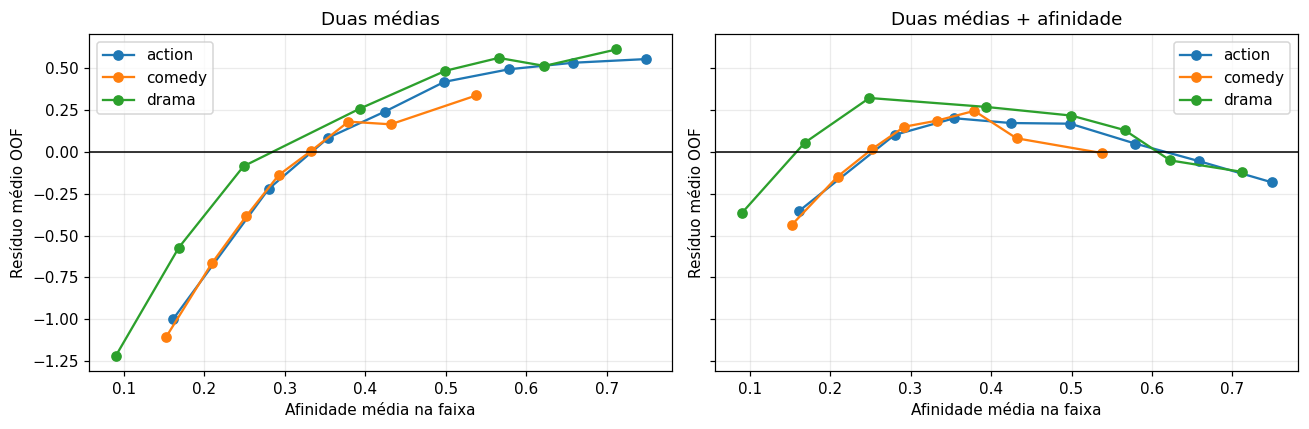

In [5]:
candidate_bins = residual_by_bin('Duas médias + afinidade')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, table, title in zip(axes, [baseline_bins, candidate_bins], candidates):
    for genre in genres:
        sub = table[table['genero'].eq(genre)]
        ax.plot(sub['afinidade_media'], sub['residuo_medio'], 'o-', label=genre)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(title=title, xlabel='Afinidade média na faixa', ylabel='Resíduo médio OOF')
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Conclusão do grupo

- O ganho em RMSE é relevante e consistente?
- O padrão dos resíduos diminuiu nos três gêneros?
- Restou curvatura que motive testar afinidade²?

**Respostas, com base na execução registrada abaixo.** O ganho é grande e consistente: o RMSE caiu de 0,8396 para 0,6601 (redução de 0,1795), com menor erro nas 25 partições. O padrão crescente nos resíduos diminuiu, mas restou uma curvatura: resíduos negativos nas menores afinidades e positivos nas faixas intermediárias. Isso motiva testar afinidade².

## Registro reproduzível desta execução

Salvamos previsões OOF por repetição, erros por partição, configurações selecionadas, versões e identificadores dos dados e do código em `results/rodada_atual`. Esses arquivos não se misturam aos resultados históricos.

In [6]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.current_results import save_run
save_run(ROOT, '04_hipotese_afinidade', df, y, predictions_by_repeat, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP, globals().get('selections'))

Resultados verificados e salvos em /Users/mrm/Documents/Disciplinas/Apredizagem Estatística/movie-rating-prediction/results/rodada_atual/04_hipotese_afinidade.json


## Leitura da execução de 15 de novembro de 2026

Acrescentar afinidade reduziu o RMSE de **0,839575 para 0,660065**. O gráfico mostra forte redução do padrão crescente anterior, mas os resíduos ainda são negativos nas menores afinidades e positivos nas faixas intermediárias. A contribuição linear da afinidade ajuda, porém não representa toda a forma observada. Essa curvatura motiva o teste quadrático do notebook 05; não prova que uma transformação específica será suficiente.

Esta leitura se refere à execução salva nesta rodada. Desvios e contagens são descritivos, não testes independentes. Revisar os números e o texto se dados, código ou configuração mudarem. As questões do grupo permanecem abertas à discussão.